Note: you may need to restart the kernel to use updated packages.
        Company     Ticker                                 Stockport presence  \
0  BT Group plc  LON: BT.A  Large service and engineering operations withi...   
1       BASF SE   ETR: BAS  UK headquarters and central UK business hub at...   
2     adidas AG   ETR: ADS  UK national distribution and administrative of...   

                                Investment relevance  
0  UK telecommunications incumbent; dividend-orie...  
1  Global chemicals major; Stockport houses UK sa...  
2  Global sportswear company with a major UK oper...  
['Company', 'Ticker', 'Stockport presence', 'Investment relevance']
Silhouette score: 0.059

Cluster counts:
Cluster
0    2
1    1
Name: count, dtype: int64
Cluster 0: uk, stockport, global, etr, major, national, operational, offices north, offices, office stockport
Cluster 1: bt, large, uk telecommunications, dividend oriented, oriented large, oriented, operations borough, bt lon, cap,

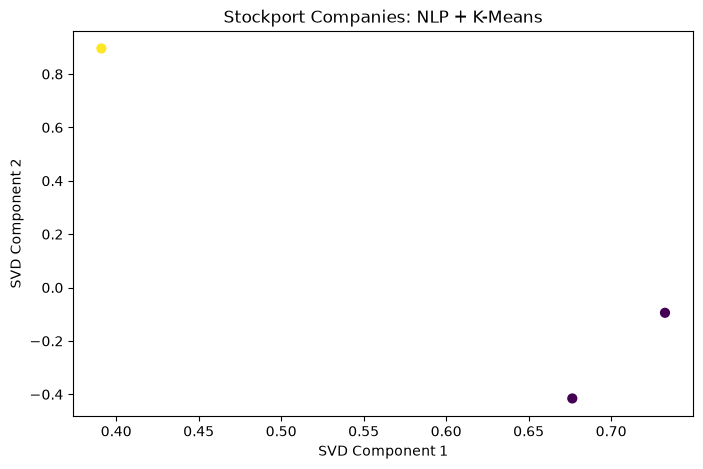

Saved: Stockport_Companies_Clustered.csv


In [1]:
# 1. Install libraries (run once)
%pip install pandas scikit-learn matplotlib seaborn

# 2. Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import silhouette_score

# 3. Load dataset
df = pd.read_csv("Stockport_Linked_Listed_Companies.csv", encoding="utf-8-sig")
print(df.head())
print(df.columns.tolist())

# 4. Select text columns automatically
text_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
if not text_cols:
    raise ValueError("Dataset has no text columns.")

df[text_cols] = df[text_cols].fillna("").astype(str)
df["text"] = df[text_cols].agg(" ".join, axis=1).str.lower()
df = df[df["text"].str.strip().ne("")].copy()

# 5. NLP preprocessing and TF-IDF
stop_words = list(ENGLISH_STOP_WORDS.union({
    "ltd", "limited", "plc", "llp", "company", "group"
}))

tfidf = TfidfVectorizer(
    stop_words=stop_words,
    max_features=3000,
    ngram_range=(1, 2)
)
X = tfidf.fit_transform(df["text"])

# 6. K-Means clustering
if X.shape[0] < 3:
    raise ValueError("At least 3 company records are required.")

k = min(4, X.shape[0] - 1)
model = KMeans(n_clusters=k, random_state=42, n_init=10)
df["Cluster"] = model.fit_predict(X)

# 7. Evaluate clusters
if len(set(df["Cluster"])) > 1 and len(set(df["Cluster"])) < len(df):
    print("Silhouette score:",
          round(silhouette_score(X, df["Cluster"], metric="cosine"), 3))

print("\nCluster counts:")
print(df["Cluster"].value_counts().sort_index())

# 8. Display top keywords per cluster
terms = tfidf.get_feature_names_out()
for i, center in enumerate(model.cluster_centers_):
    keywords = terms[center.argsort()[-10:][::-1]]
    print(f"Cluster {i}: {', '.join(keywords)}")

# 9. Visualize clusters
if X.shape[1] >= 2 and X.shape[0] >= 2:
    coords = TruncatedSVD(n_components=2, random_state=42).fit_transform(X)
    plt.figure(figsize=(8, 5))
    plt.scatter(coords[:, 0], coords[:, 1],
                c=df["Cluster"], cmap="viridis", s=40)
    plt.title("Stockport Companies: NLP + K-Means")
    plt.xlabel("SVD Component 1")
    plt.ylabel("SVD Component 2")
    plt.show()

# 10. Save results
df.to_csv("Stockport_Companies_Clustered.csv", index=False)
print("Saved: Stockport_Companies_Clustered.csv")